In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

cols = ["id", "diagnosis"]
base = ["radius","texture","perimeter","area","smoothness",
        "compactness","concavity","concave_points","symmetry","fractal_dim"]
for s in ["mean","se","worst"]:
    cols += [f"{b}_{s}" for b in base]

df = pd.read_csv("../data/wdbc.data", header=None, names=cols).drop(columns="id")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
print(df.shape)
df.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dim_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# 80% (train+val) / 20% test
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# del 80%: 75% train / 25% validación → 60/20/20 en total
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(nombre, len(yy), "malignos:", round(yy.mean(), 3))

train 341 malignos: 0.372
val 114 malignos: 0.377
test 114 malignos: 0.368


Se dividió el dataset en 60% entrenamiento, 20% validación y 20% prueba, de forma estratificada y con semilla fija (42), de modo que cada subconjunto conserva la proporción de clases (~37% malignos).

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# --- Referencia: regresión logística ---
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=SEED))
])
grid_lr = {"clf__C": [0.01, 0.1, 1, 10, 100]}
gs_lr = GridSearchCV(pipe_lr, grid_lr, cv=cv, scoring="f1", n_jobs=1)
gs_lr.fit(X_train, y_train)

# --- Naive Bayes gaussiano ---
pipe_nb = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", GaussianNB())
])
grid_nb = {"clf__var_smoothing": np.logspace(-11, -5, 7)}
gs_nb = GridSearchCV(pipe_nb, grid_nb, cv=cv, scoring="f1", n_jobs=1)
gs_nb.fit(X_train, y_train)

for nombre, gs in [("Regresión logística", gs_lr), ("Naive Bayes", gs_nb)]:
    i = gs.best_index_
    print(nombre, gs.best_params_,
          "F1 CV: %.4f ± %.4f" % (gs.best_score_, gs.cv_results_["std_test_score"][i]),
          "| F1 val: %.4f" % gs.score(X_val, y_val))

Regresión logística {'clf__C': 0.1} F1 CV: 0.9636 ± 0.0276 | F1 val: 0.9762
Naive Bayes {'clf__var_smoothing': np.float64(1e-11)} F1 CV: 0.8886 ± 0.0520 | F1 val: 0.9412


### Resultados: regresión logística y Naive Bayes

*Espacio de búsqueda:* Regresión logística: C ∈ {0.01, 0.1, 1, 10, 100}.
Naive Bayes gaussiano: var_smoothing ∈ logspace(-11, -5, 7). Validación
cruzada estratificada de 5 folds, métrica F1, semilla 42.

*Resultados:* La regresión logística (C = 0.1) obtuvo F1 de 0.9636 ± 0.0276
en validación cruzada y 0.9762 en el conjunto de validación. Naive Bayes
(var_smoothing = 1e-11) obtuvo 0.8886 ± 0.0520 y 0.9412, respectivamente.

*Interpretación:* Naive Bayes asume independencia condicional entre las
variables y normalidad dentro de cada clase. El análisis exploratorio mostró
que radio, perímetro y área tienen correlación cercana a 0.99, y que
compacidad, concavidad y puntos cóncavos también están muy correlacionadas,
por lo que el supuesto no se cumple. Esto explica en parte su menor
desempeño y su mayor variabilidad entre folds frente al modelo de referencia.
El valor óptimo de var_smoothing quedó en el extremo de la malla, y como el
parámetro apenas afecta el resultado, la diferencia entre valores es mínima.


In [5]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.svm import SVC

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(probability=True, random_state=SEED))
])

grid_svm = [
    {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10, 100]},
    {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100],
     "clf__gamma": ["scale", 0.001, 0.01, 0.1]},
]
gs_svm = GridSearchCV(pipe_svm, grid_svm, cv=cv, scoring="f1", n_jobs=1)
gs_svm.fit(X_train, y_train)

i = gs_svm.best_index_
print("SVM", gs_svm.best_params_,
      "F1 CV: %.4f ± %.4f" % (gs_svm.best_score_, gs_svm.cv_results_["std_test_score"][i]),
      "| F1 val: %.4f" % gs_svm.score(X_val, y_val))

SVM {'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'} F1 CV: 0.9637 ± 0.0266 | F1 val: 0.9655


### Resultados: máquina de soporte vectorial (SVM)

*Espacio de búsqueda.* Kernel ∈ {lineal, RBF}; C ∈ {0.1, 1, 10, 100} para
ambos kernels; gamma ∈ {scale, 0.001, 0.01, 0.1} solo para RBF (20
combinaciones en total). Validación cruzada estratificada de 5 folds,
métrica F1, semilla 42, con escalado estándar dentro del Pipeline.

*Resultados.* La mejor configuración fue el kernel RBF con C = 10 y
gamma = 0.01, con un F1 de 0.9637 ± 0.0266 en validación cruzada y 0.9655
en el conjunto de validación.

*Comparación con los modelos anteriores.*

| Modelo | Hiperparámetros | F1 (CV) | F1 (validación) |
|---|---|---|---|
| Regresión logística (referencia) | C = 0.1 | 0.9636 ± 0.0276 | 0.9762 |
| Naive Bayes gaussiano | var_smoothing = 1e-11 | 0.8886 ± 0.0520 | 0.9412 |
| SVM (RBF) | C = 10, gamma = 0.01 | 0.9637 ± 0.0266 | 0.9655 |

*Interpretación.* La regresión logística y el SVM obtuvieron un F1 en
validación cruzada prácticamente idéntico (diferencia de 0.0001), mucho
menor que la desviación estándar entre folds, por lo que con estos datos no
es posible afirmar que uno supere al otro. Que un modelo lineal iguale al
SVM con kernel RBF sugiere que las clases son casi linealmente separables.
Naive Bayes quedó por debajo y con mayor variabilidad, lo que es coherente
con la fuerte correlación entre variables observada en el análisis
exploratorio.


In [6]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.neural_network import MLPClassifier

pipe_mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(max_iter=1000, early_stopping=True,
                          validation_fraction=0.15, n_iter_no_change=20,
                          random_state=SEED))
])

grid_mlp = {
    "clf__hidden_layer_sizes": [(16,), (32,), (32, 16)],
    "clf__activation": ["relu", "tanh"],
    "clf__alpha": [1e-4, 1e-3, 1e-2],
}
gs_mlp = GridSearchCV(pipe_mlp, grid_mlp, cv=cv, scoring="f1", n_jobs=1)
gs_mlp.fit(X_train, y_train)

i = gs_mlp.best_index_
print("MLP", gs_mlp.best_params_,
      "F1 CV: %.4f ± %.4f" % (gs_mlp.best_score_, gs_mlp.cv_results_["std_test_score"][i]),
      "| F1 val: %.4f" % gs_mlp.score(X_val, y_val))

MLP {'clf__activation': 'tanh', 'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (32, 16)} F1 CV: 0.9477 ± 0.0103 | F1 val: 0.9524


### Resultados: perceptrón multicapa (MLP)

*Arquitectura y justificación.* Se probaron redes pequeñas (una capa de
16 o 32 neuronas, o dos capas de 32 y 16), porque el conjunto de
entrenamiento tiene solo 341 muestras y una red grande tiende a
sobreajustarse. Se compararon las activaciones ReLU y tanh. Para evitar el
sobreajuste se usó regularización L2 (alpha ∈ {1e-4, 1e-3, 1e-2}) y
detención temprana (15% del entrenamiento como validación interna,
paciencia de 20 iteraciones). El escalado estándar va dentro del Pipeline.

*Espacio de búsqueda.* hidden_layer_sizes ∈ {(16,), (32,), (32, 16)};
activation ∈ {relu, tanh}; alpha ∈ {1e-4, 1e-3, 1e-2} (18 combinaciones).
Validación cruzada estratificada de 5 folds, métrica F1, semilla 42.

*Resultados.* La mejor configuración fue tanh, alpha = 1e-4 y capas
(32, 16), con F1 de 0.9477 ± 0.0103 en validación cruzada y 0.9524 en el
conjunto de validación.

*Interpretación.* El MLP obtuvo un F1 medio menor que la regresión
logística y el SVM, aunque con menor variabilidad entre folds. Con pocas
muestras y clases casi linealmente separables, la mayor flexibilidad de la
red no aporta ventaja.


In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)

modelos = {
    "Reg. logística (ref.)": gs_lr.best_estimator_,
    "Naive Bayes": gs_nb.best_estimator_,
    "SVM (RBF)": gs_svm.best_estimator_,
    "MLP": gs_mlp.best_estimator_,
}

filas = []
for nombre, m in modelos.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    filas.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, pred),
        "Precisión": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba),
    })

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
tabla

,Exactitud,Precisión,Recall,F1,AUC
Modelo,,,,,
Reg. logística (ref.),0.9825,1.0000,0.9524,0.9756,0.9977
Naive Bayes,0.9211,0.9231,0.8571,0.8889,0.9897
SVM (RBF),0.9825,1.0000,0.9524,0.9756,0.9957
MLP,0.9561,0.9744,0.9048,0.9383,0.9954


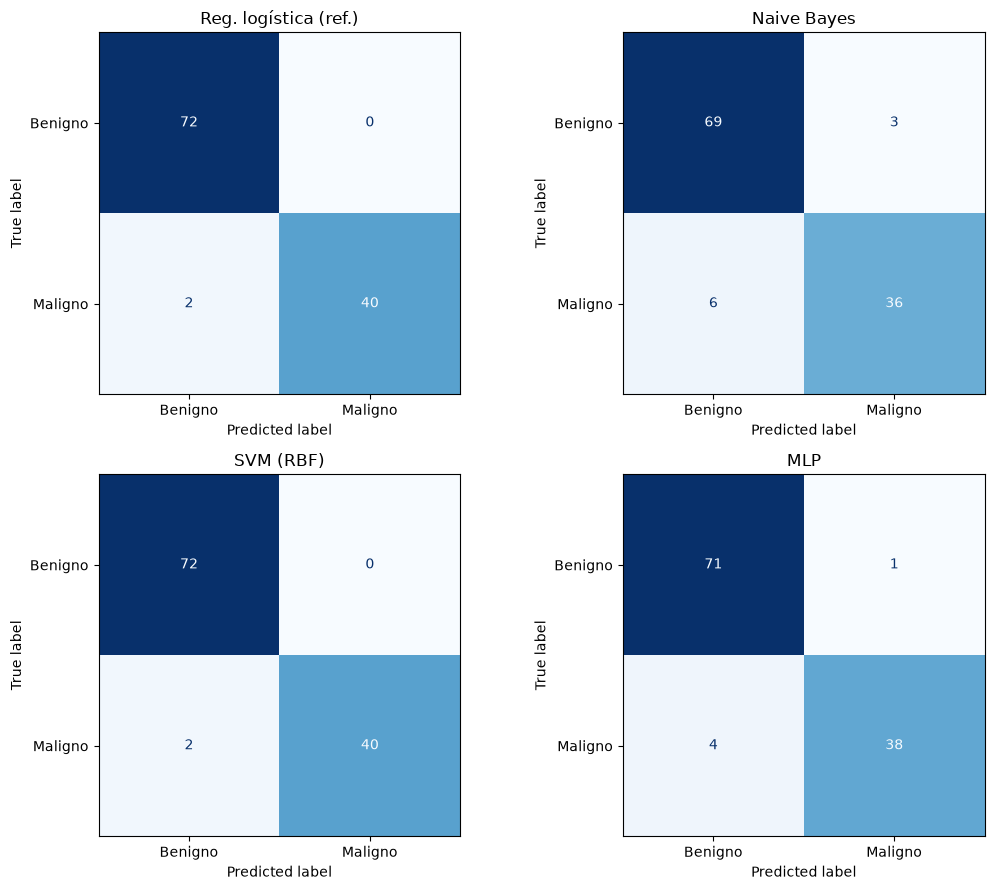

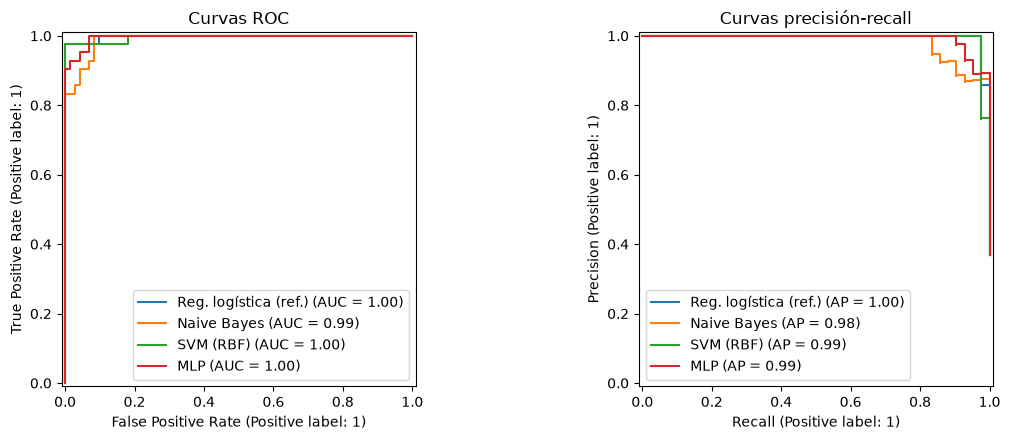

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for a, (nombre, m) in zip(ax.ravel(), modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=["Benigno", "Maligno"],
        cmap="Blues", ax=a, colorbar=False)
    a.set_title(nombre)
plt.tight_layout()
plt.savefig("../reports/figures/matrices_confusion.png", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, m in modelos.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=nombre, ax=ax[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=nombre, ax=ax[1])
ax[0].set_title("Curvas ROC")
ax[1].set_title("Curvas precisión-recall")
plt.tight_layout()
plt.savefig("../reports/figures/roc_pr.png", dpi=150)
plt.show()

### Evaluación en el conjunto de prueba

Cada modelo se evaluó una sola vez sobre el conjunto de prueba (114
muestras, 42 malignas) con los hiperparámetros elegidos en validación
cruzada.

| Modelo | Exactitud | Precisión | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Regresión logística (ref.) | 0.9825 | 1.0000 | 0.9524 | 0.9756 | 0.9977 |
| Naive Bayes | 0.9211 | 0.9231 | 0.8571 | 0.8889 | 0.9897 |
| SVM (RBF) | 0.9825 | 1.0000 | 0.9524 | 0.9756 | 0.9957 |
| MLP | 0.9561 | 0.9744 | 0.9048 | 0.9383 | 0.9954 |

La regresión logística y el SVM obtuvieron el mismo desempeño (dos falsos
negativos y ningún falso positivo). Naive Bayes fue el de menor desempeño,
con el recall más bajo, lo cual es relevante en este problema porque un
falso negativo implica un tumor maligno no detectado. Las curvas ROC y
precisión-recall son muy similares entre modelos (AUC ≥ 0.99), por lo que
las diferencias se deben principalmente al umbral de decisión. Dado el
tamaño reducido del conjunto de prueba, estas diferencias deben
interpretarse con cautela y se contrastan en la siguiente sección con
repeticiones bajo distintas semillas.

In [11]:
import time
from sklearn.base import clone

semillas = [0, 1, 2, 3, 4]

mallas = {
    "Reg. logística": (pipe_lr, grid_lr),
    "Naive Bayes": (pipe_nb, grid_nb),
    "SVM": (pipe_svm, grid_svm),
    "MLP": (pipe_mlp, grid_mlp),
}

resultados = []
for s in semillas:
    t0 = time.time()
    Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.20, stratify=y, random_state=s)
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
    for nombre, (pipe, grid) in mallas.items():
        gs = GridSearchCV(clone(pipe), grid, cv=cv_s, scoring="f1", n_jobs=1)
        gs.fit(Xa, ya)
        pred = gs.predict(Xt)
        resultados.append({
            "semilla": s, "Modelo": nombre,
            "Exactitud": accuracy_score(yt, pred),
            "Recall": recall_score(yt, pred),
            "F1": f1_score(yt, pred),
        })
    print(f"semilla {s} lista ({time.time()-t0:.0f} s)")

res = pd.DataFrame(resultados)
resumen = res.groupby("Modelo")[["Exactitud", "Recall", "F1"]].agg(["mean", "std"]).round(4)
resumen

semilla 0 lista (74 s)
semilla 1 lista (72 s)
semilla 2 lista (70 s)
semilla 3 lista (63 s)
semilla 4 lista (62 s)


Exactitud          Recall              F1        
                    mean     std    mean     std    mean     std
Modelo                                                          
MLP               0.9404  0.0114  0.9238  0.0458  0.9195  0.0143
Naive Bayes       0.9193  0.0218  0.8810  0.0337  0.8897  0.0289
Reg. logística    0.9684  0.0211  0.9286  0.0607  0.9551  0.0316
SVM               0.9632  0.0157  0.9238  0.0391  0.9485  0.0225

### Variabilidad con múltiples semillas

Para evaluar si las diferencias entre modelos son reales, se repitió todo
el procedimiento (división 80/20 estratificada, búsqueda de hiperparámetros
con validación cruzada de 5 folds y evaluación en prueba) con cinco semillas
(0 a 4). La búsqueda en cada repetición usó únicamente el 80% de
entrenamiento, sin conjunto de validación aparte.

| Modelo | Exactitud | Recall | F1 |
|---|---|---|---|
| Regresión logística | 0.9684 ± 0.0211 | 0.9286 ± 0.0607 | 0.9551 ± 0.0316 |
| SVM | 0.9632 ± 0.0157 | 0.9238 ± 0.0391 | 0.9485 ± 0.0225 |
| MLP | 0.9404 ± 0.0114 | 0.9238 ± 0.0458 | 0.9195 ± 0.0143 |
| Naive Bayes | 0.9193 ± 0.0218 | 0.8810 ± 0.0337 | 0.8897 ± 0.0289 |

Los valores son media ± desviación estándar entre semillas. La regresión
logística y el SVM tienen diferencias menores que su desviación estándar,
por lo que no pueden considerarse distintos. El MLP muestra una tendencia a
un menor F1, mientras que Naive Bayes es consistentemente el de menor
desempeño. El desempeño de la regresión logística con la semilla 42
(F1 = 0.9756) resultó algo mayor que su promedio entre semillas, lo que
muestra que un único conjunto de prueba de 114 muestras puede ser optimista.
El recall es la métrica más variable, porque cada conjunto de prueba contiene
solo unos 42 casos malignos.

In [8]:
errores = {}
for nombre, m in modelos.items():
    pred = m.predict(X_test)
    mal = X_test.index[pred != y_test]
    errores[nombre] = set(mal)
    fn = ((pred == 0) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    print(f"{nombre}: {len(mal)} errores | falsos negativos: {fn} | falsos positivos: {fp}")

# casos que fallan en 3 o 4 modelos
from collections import Counter
conteo = Counter(i for s in errores.values() for i in s)
dificiles = [i for i, c in conteo.items() if c >= 3]
print("\nCasos dificiles (fallan en >= 3 modelos):", dificiles)

cols_clave = ["radius_mean", "texture_mean", "concavity_mean",
              "concave_points_mean", "area_worst", "concave_points_worst"]
comp = X_test.loc[dificiles, cols_clave].copy()
comp["real"] = y_test.loc[dificiles]
comp["prob_maligno_LR"] = modelos["Reg. logística (ref.)"].predict_proba(X_test.loc[dificiles])[:, 1].round(3)

# promedios por clase en el conjunto de prueba, para comparar
medias = X_test[cols_clave].groupby(y_test).mean().round(3)
display(comp)
display(medias)

Reg. logística (ref.): 2 errores | falsos negativos: 2 | falsos positivos: 0
Naive Bayes: 9 errores | falsos negativos: 6 | falsos positivos: 3
SVM (RBF): 2 errores | falsos negativos: 2 | falsos positivos: 0
MLP: 5 errores | falsos negativos: 4 | falsos positivos: 1

Casos dificiles (fallan en >= 3 modelos): [73, 205]


,radius_mean,texture_mean,concavity_mean,concave_points_mean,area_worst,concave_points_worst,real,prob_maligno_LR
73,13.80,15.79,0.07789,0.05069,812.4,0.1383,1,0.174
205,15.12,16.68,0.07550,0.04079,989.5,0.1252,1,0.406


,radius_mean,texture_mean,concavity_mean,concave_points_mean,area_worst,concave_points_worst
diagnosis,,,,,,
0,12.111,17.385,0.046,0.028,547.369,0.072
1,17.164,21.168,0.158,0.085,1343.624,0.177


### Análisis de errores

Con la partición de la semilla 42, la regresión logística y el SVM
cometieron 2 errores (ambos falsos negativos), el MLP 5 (4 falsos
negativos y 1 falso positivo) y Naive Bayes 9 (6 falsos negativos y 3
falsos positivos). En todos los modelos predominan los falsos negativos,
es decir, tumores malignos clasificados como benignos, que es el error más
grave en un contexto clínico porque implica un diagnóstico no detectado.

Dos muestras (índices 73 y 205) fueron clasificadas erróneamente por al
menos tres de los cuatro modelos. Ambas son malignas, pero sus
características se parecen más a las de los tumores benignos: por ejemplo,
la muestra 73 tiene concavidad media de 0.078 y puntos cóncavos medios de
0.051, frente a promedios de 0.158 y 0.085 en los malignos del conjunto de
prueba (0.046 y 0.028 en los benignos), y radios medios de 13.8 y 15.1,
intermedios entre ambas clases (12.1 y 17.2). La regresión logística les
asignó probabilidades de malignidad de apenas 0.17 y 0.41. Esto sugiere
que se trata de casos en la frontera entre clases, donde ningún modelo
dispone de información suficiente para separarlos con las variables
disponibles.

Naive Bayes cometió además errores que los otros modelos no, lo que es
coherente con la violación del supuesto de independencia condicional entre
variables fuertemente correlacionadas.